In [1]:
from Bio import AlignIO
import numpy as np
import pandas as pd
from Bio.Align import substitution_matrices

def compute_gappiness(alignment):
    alignment_array = np.array([list(record.seq) for record in alignment])
    num_sequences = alignment_array.shape[0]
    alignment_length = alignment_array.shape[1]
    gappiness_scores = []

    for seq_index, sequence in enumerate(alignment_array):
        gpp = 0
        for column_index in range(alignment_length):
            column = alignment_array[:, column_index]
            num_residues_in_column = np.sum(column != '-')
            is_residue_in_this_sequence = sequence[column_index] != '-'
            majority_have_gaps = num_residues_in_column < (num_sequences / 2)

            if is_residue_in_this_sequence and majority_have_gaps:
                penalty = num_sequences - num_residues_in_column
                gpp += penalty

        normalized_gpp = gpp / (alignment_length * num_sequences)
        gappiness_scores.append(normalized_gpp)

    return gappiness_scores

def compute_gap_penalty(matrix: np.ndarray):
    scores = matrix.flatten()  # get all values
    return np.min(scores) - np.std(scores)


def _compute_sequence_weights(alignment, matrix_name="NUC.4.4"):
    substitution_matrix = substitution_matrices.load(matrix_name)
    gap_penalty = compute_gap_penalty(substitution_matrix)

    alignment_array = np.array([list(record.seq.upper()) for record in alignment])
    _, alignment_length = alignment_array.shape

    weights = []

    for seq_index, current_sequence in enumerate(alignment_array):
        sequence_score = 0

        for position in range(alignment_length):
            char_s = current_sequence[position]

            for other_index, other_sequence in enumerate(alignment_array):
                if other_index == seq_index:
                    continue  # Don't compare sequence to itself

                char_o = other_sequence[position]

                # Apply gap penalty if needed
                if char_s == '-' or char_o == '-':
                    sequence_score += gap_penalty
                else:
                    try:
                        sequence_score += substitution_matrix[char_s][char_o]
                    except (KeyError, IndexError):
                        try:
                            sequence_score += substitution_matrix[char_o][char_s]
                        except (KeyError, IndexError):
                            sequence_score += gap_penalty  # Default to gap penalty

        weights.append(sequence_score)

    return weights

def compute_sequence_weights(alignment, matrix_name="NUC.4.4"):
    substitution_matrix = substitution_matrices.load(matrix_name)
    gap_penalty = compute_gap_penalty(substitution_matrix)

    # Convert alignment to NumPy array of characters
    alignment_array = np.array([list(record.seq.upper()) for record in alignment])
    n_seqs, alignment_length = alignment_array.shape

    # --- Step 1: Map characters to integer indices ---
    chars = sorted(set("".join("".join(seq) for seq in alignment_array)))
    if '-' not in chars:
        chars.append('-')
    char_to_idx = {c: i for i, c in enumerate(chars)}

    # Build substitution matrix as a NumPy array
    subst_array = np.full((len(chars), len(chars)), gap_penalty, dtype=float)
    for a, a_idx in char_to_idx.items():
        for b, b_idx in char_to_idx.items():
            try:
                subst_array[a_idx, b_idx] = substitution_matrix[a][b]
            except (KeyError, IndexError):
                try:
                    subst_array[a_idx, b_idx] = substitution_matrix[b][a]
                except (KeyError, IndexError):
                    subst_array[a_idx, b_idx] = gap_penalty

    # --- Step 2: Convert alignment to integer matrix ---
    int_alignment = np.vectorize(char_to_idx.get)(alignment_array)

    # --- Step 3: Compute pairwise scores with broadcasting ---
    weights = np.zeros(n_seqs, dtype=float)

    for i in range(n_seqs):
        # Compare seq i to all others at once (broadcast over positions)
        seq_i = int_alignment[i]  # shape (L,)
        others = int_alignment    # shape (N, L)

        # Look up scores for all pairwise char comparisons
        scores = subst_array[seq_i[:, None], others.T]  # shape (L, N)

        # Remove self-comparison (i vs i)
        scores[:, i] = 0

        # Sum across positions and other sequences
        weights[i] = scores.sum()

    return weights.tolist()


def evalmsa(filepath, matrix_name="NUC.4.4"):
    alignment = AlignIO.read(filepath, "fasta")
    gappiness = compute_gappiness(alignment)
    weights = compute_sequence_weights(alignment, matrix_name)

    # Normalize
    norm_weights = (weights - np.min(weights)) / (np.max(weights) - np.min(weights))
    norm_gpp = (gappiness - np.min(gappiness)) / (np.max(gappiness) - np.min(gappiness))

    df = pd.DataFrame({
        'Sequence_ID': [record.id for record in alignment],
        'Weight': weights,
        'Normalized_Weight': norm_weights,
        'Gappiness': gappiness,
        'Normalized_Gappiness': norm_gpp
    })

    df = df.sort_values('Normalized_Gappiness', ascending=False)
    return df

# Example usage:
df = evalmsa("Alignments with outliers/NUCLEOTIDE/primates_aligned.fas")
# df.to_csv("evalmsa_results.csv", index=False)
df

,Sequence_ID,Weight,Normalized_Weight,Gappiness,Normalized_Gappiness
0,gi|82395885|gb|DQ273698.1|_Crocodylus_porosus_...,248685.820168,0.000000,0.048086,1.000000
7,gi|49146236|ref|NC_005943.1|_Macaca_mulatta_mi...,574464.342258,0.695054,0.004879,0.098645
8,gi|14010693|ref|NC_002764.1|_Macaca_sylvanus_m...,576578.195735,0.699564,0.004826,0.097544
12,gi|5835638|ref|NC_001992.1|_Papio_hamadryas_mi...,563189.168207,0.670998,0.003129,0.062151
13,gi|5835163|ref|NC_001646.1|_Pongo_pygmaeus_mit...,615976.651155,0.783621,0.001770,0.033785
6,gi|5835820|ref|NC_002082.1|_Hylobates_lar_mito...,607309.904772,0.765130,0.001003,0.017782
2,gi|195952353|ref|NC_011120.1|_Gorilla_gorilla_...,680369.755618,0.921005,0.000394,0.005080
9,gi|281188365|gb|GU189661.1|_Pan_paniscus_isola...,711073.039779,0.986511,0.000308,0.003302
11,gi|1262390|emb|X93335.1|_Pan_troglodytes_mitoc...,713418.794824,0.991515,0.000284,0.002794
1,gi|5835149|ref|NC_001645.1|_Gorilla_gorilla_mi...,675845.561771,0.911352,0.000284,0.002794


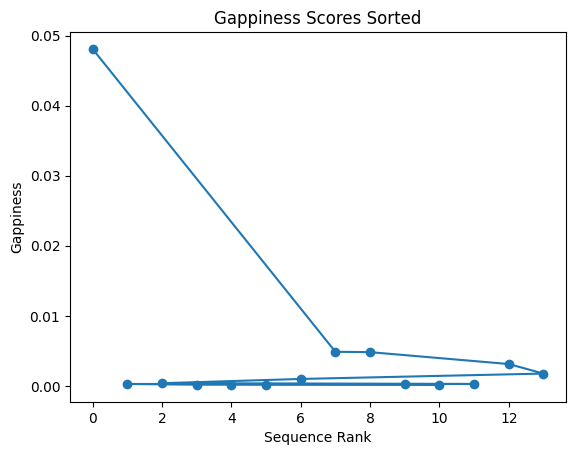

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline

sorted_scores = df['Gappiness'].sort_values(ascending=False, ignore_index=True)
plt.plot(sorted_scores, marker='o')
plt.title("Gappiness Scores Sorted")
plt.xlabel("Sequence Rank")
plt.ylabel("Gappiness")
plt.show()

In [1]:
from src import alignment
import profile

res = alignment.calculate_gappiness('data/cox2_th_outgroup/outgroups/cox2_th_outgroup-sintax.fasta')
res

,accession,weight,weight_normalized,gappiness,gappiness_normalized
0,"NC_002553.1;tax=d:Eukaryota,k:nan,p:nan,c:ince...",-1073.308064,0.000000,0.177264,1.000000
1,"OP168900.1;tax=d:Eukaryota,k:Dictyostelia,p:Ev...",1464.691936,0.084820,0.118969,0.671141
2,"OP749982.1;tax=d:Eukaryota,k:Dictyostelia,p:Ev...",2598.691936,0.122718,0.118969,0.671141
3,"NC_006862.1;tax=d:Eukaryota,k:Dictyostelia,p:E...",534.502421,0.053733,0.102710,0.579418
4,"NC_010653.1;tax=d:Eukaryota,k:Dictyostelia,p:E...",3180.502421,0.142163,0.102710,0.579418
...,...,...,...,...,...
80,"PV153509.1;tax=d:Eukaryota,k:nan,p:Rhodophyta,...",11694.849208,0.426712,0.000000,0.000000
81,"PV156529.1;tax=d:Eukaryota,k:nan,p:Rhodophyta,...",11397.849208,0.416787,0.000000,0.000000
82,"PV156531.1;tax=d:Eukaryota,k:nan,p:Rhodophyta,...",12270.849208,0.445962,0.000000,0.000000
83,"PV475520.1;tax=d:Eukaryota,k:Ochrophyta,p:nan,...",7041.849208,0.271209,0.000000,0.000000


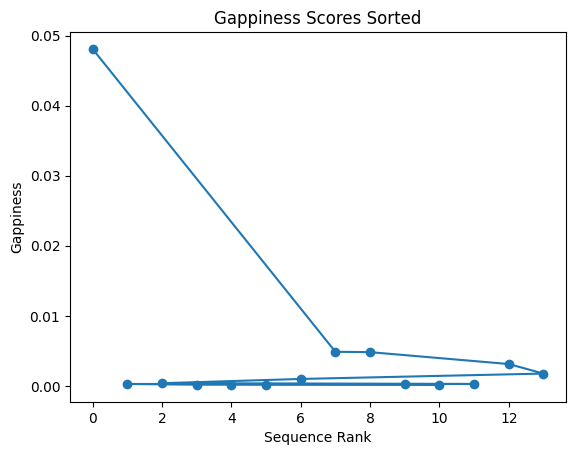

In [4]:
import matplotlib.pyplot as plt
%matplotlib inline

sorted_scores = res['gappiness'].sort_values(ascending=False, ignore_index=True)
plt.plot(sorted_scores, marker='o')
plt.title("Gappiness Scores Sorted")
plt.xlabel("Sequence Rank")
plt.ylabel("Gappiness")
plt.show()